In [2]:
# Uber Fare Prediction using Machine Learning

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error
)

In [3]:
df = pd.read_csv("uber.csv")

print("Original Dataset Shape:", df.shape)
print(df.head())
print("\nMissing Values:\n", df.isnull().sum())


df.drop(columns=["Unnamed: 0", "key"],
        errors="ignore", inplace=True)

df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)

df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

Original Dataset Shape: (200000, 9)
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.

In [4]:
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"].between(1, 6)) &
    (df["pickup_longitude"].between(-180, 180)) &
    (df["dropoff_longitude"].between(-180, 180)) &
    (df["pickup_latitude"].between(-90, 90)) &
    (df["dropoff_latitude"].between(-90, 90))
].copy()

df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year
df["weekday"] = df["pickup_datetime"].dt.dayofweek

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (np.sin(dlat / 2) ** 2 +
         np.cos(lat1) * np.cos(lat2) *
         np.sin(dlon / 2) ** 2)

    return 6371 * 2 * np.arcsin(
        np.sqrt(np.clip(a, 0, 1))
    )

df["distance_km"] = haversine(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

df = df[
    df["pickup_longitude"].between(-75, -72) &
    df["dropoff_longitude"].between(-75, -72) &
    df["pickup_latitude"].between(40, 42) &
    df["dropoff_latitude"].between(40, 42) &
    (df["distance_km"] > 0) &
    (df["distance_km"] <= 100)
].copy()

print("\nCleaned Dataset Shape:", df.shape)
print(df.head())


Cleaned Dataset Shape: (193059, 13)
   fare_amount           pickup_datetime  pickup_longitude  pickup_latitude  \
0          7.5 2015-05-07 19:52:06+00:00        -73.999817        40.738354   
1          7.7 2009-07-17 20:04:56+00:00        -73.994355        40.728225   
2         12.9 2009-08-24 21:45:00+00:00        -74.005043        40.740770   
3          5.3 2009-06-26 08:22:21+00:00        -73.976124        40.790844   
4         16.0 2014-08-28 17:47:00+00:00        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  hour  day  month  \
0         -73.999512         40.723217                1    19    7      5   
1         -73.994710         40.750325                1    20   17      7   
2         -73.962565         40.772647                1    21   24      8   
3         -73.965316         40.803349                3     8   26      6   
4         -73.973082         40.761247                5    17   28      8   

   year  weekday  distanc

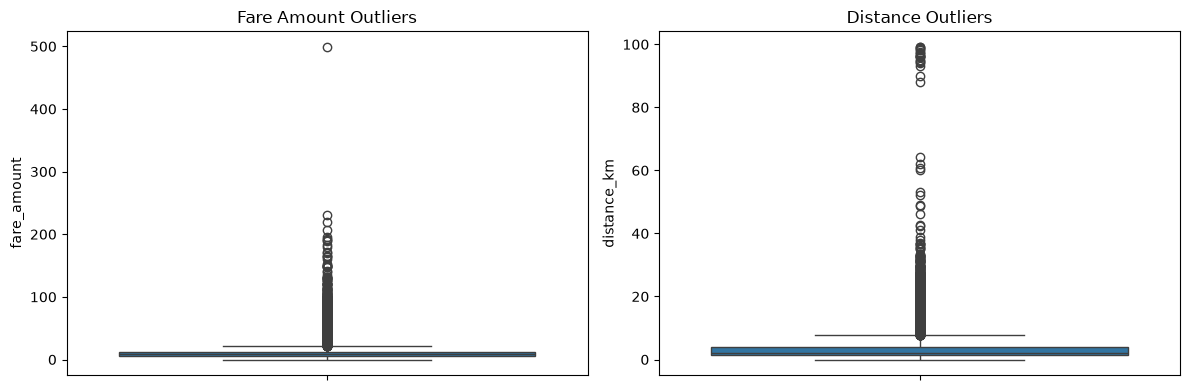

In [5]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=df["fare_amount"])
plt.title("Fare Amount Outliers")

plt.subplot(1, 2, 2)
sns.boxplot(y=df["distance_km"])
plt.title("Distance Outliers")

plt.tight_layout()
plt.show()

In [6]:
for col in ["fare_amount", "distance_km"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    print(f"{col}: Outlier limits = {lower:.2f}, {upper:.2f}")

for col in ["fare_amount", "distance_km"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = max(0, Q1 - 1.5 * IQR)
    upper = Q3 + 1.5 * IQR

    df = df[df[col].between(lower, upper)].copy()

print("Shape after outlier removal:", df.shape)

features = [
    "fare_amount", "distance_km", "passenger_count",
    "hour", "day", "month", "year", "weekday"
]

fare_amount: Outlier limits = -3.75, 22.25
distance_km: Outlier limits = -2.71, 7.93
Shape after outlier removal: (168801, 13)


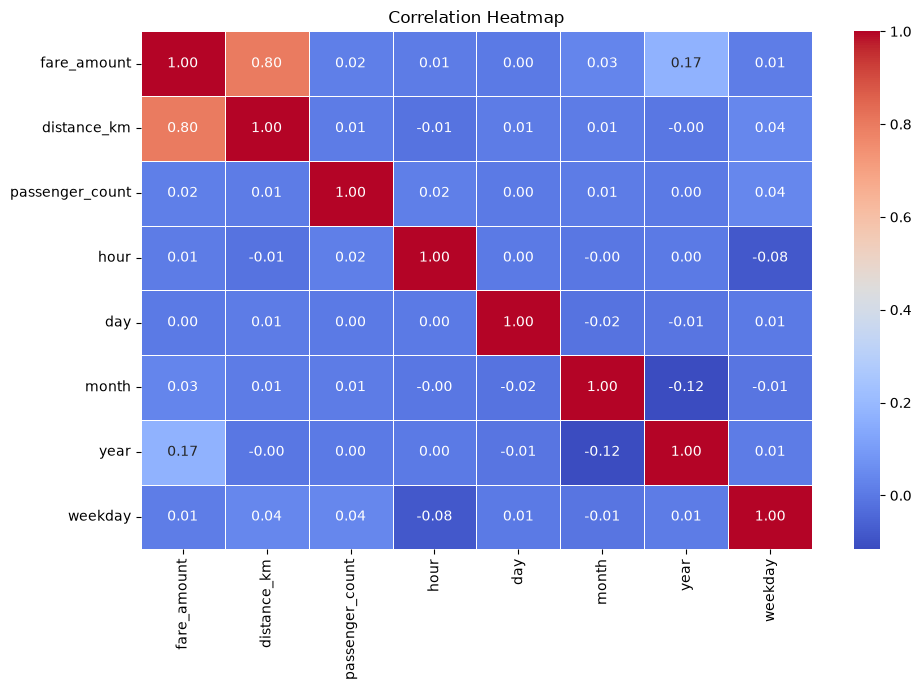


Correlation with Fare Amount:
fare_amount        1.000000
distance_km        0.795088
year               0.173408
month              0.032705
passenger_count    0.016832
weekday            0.013102
hour               0.006843
day                0.004878
Name: fare_amount, dtype: float64


In [7]:
correlation = df[features].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation, annot=True, cmap="coolwarm",
    fmt=".2f", linewidths=0.5
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print("\nCorrelation with Fare Amount:")
print(correlation["fare_amount"].sort_values(ascending=False))

X = df[
    [
        "pickup_longitude", "pickup_latitude",
        "dropoff_longitude", "dropoff_latitude",
        "passenger_count", "distance_km",
        "hour", "day", "month", "year", "weekday"
    ]
]
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

In [8]:
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

def evaluate_model(name, actual, predicted):
    r2 = r2_score(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)

    return {
        "Model": name,
        "R2 Score": round(r2, 4),
        "RMSE": round(rmse, 4),
        "MAE": round(mae, 4)
    }

results = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, lr_pred),
    evaluate_model("Random Forest", y_test, rf_pred)
])


Model Comparison:
            Model  R2 Score   RMSE    MAE
Linear Regression    0.6695 2.1281 1.5156
    Random Forest    0.7451 1.8687 1.2890

Actual Fare: 6.5
Linear Regression Prediction: 7.34
Random Forest Prediction: 8.21


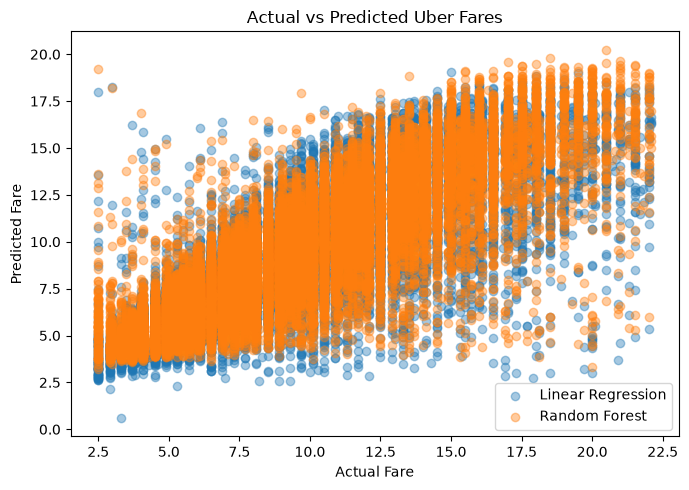

In [9]:
print("\nModel Comparison:")
print(results.to_string(index=False))

sample_ride = X_test.iloc[[0]]

print("\nActual Fare:", round(y_test.iloc[0], 2))
print("Linear Regression Prediction:",
      round(lr.predict(sample_ride)[0], 2))
print("Random Forest Prediction:",
      round(rf.predict(sample_ride)[0], 2))

plt.figure(figsize=(7, 5))
plt.scatter(y_test, lr_pred, alpha=0.4, label="Linear Regression")
plt.scatter(y_test, rf_pred, alpha=0.4, label="Random Forest")
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Uber Fares")
plt.legend()
plt.tight_layout()
plt.show()